In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080226

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] hw01_env
[学号] 20244080226
[机器指纹] 068b3410f591ad41
[RUN_ID] 20244080226-068b3410f591ad41


## 1.围绕半圆定律

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 半圆密度函数
def wigner_density(x):
    x = np.asarray(x)
    res = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    res[mask] = np.sqrt(4 - x[mask]**2) / (2 * np.pi)
    return res.item() if res.ndim == 0 else res

# 2. 生成 Wigner 矩阵
def generate_wigner(n):
    if not isinstance(n, int) or isinstance(n, bool) or n <= 0:
        raise ValueError("n 必须是正整数")
    # 方差为 1/n，标准差为 1/sqrt(n)
    A = np.random.normal(0, 1/np.sqrt(n), (n, n))
    # 对称化：保留上三角，并把严格上三角转置后加到下三角
    Z = np.triu(A) + np.triu(A, 1).T
    return Z

# 3. 获取特征值（升序）
def get_spectrum(matrix):
    # eigvalsh 专门用于对称/厄米矩阵，返回实特征值
    vals = np.linalg.eigvalsh(matrix)
    return np.sort(vals)

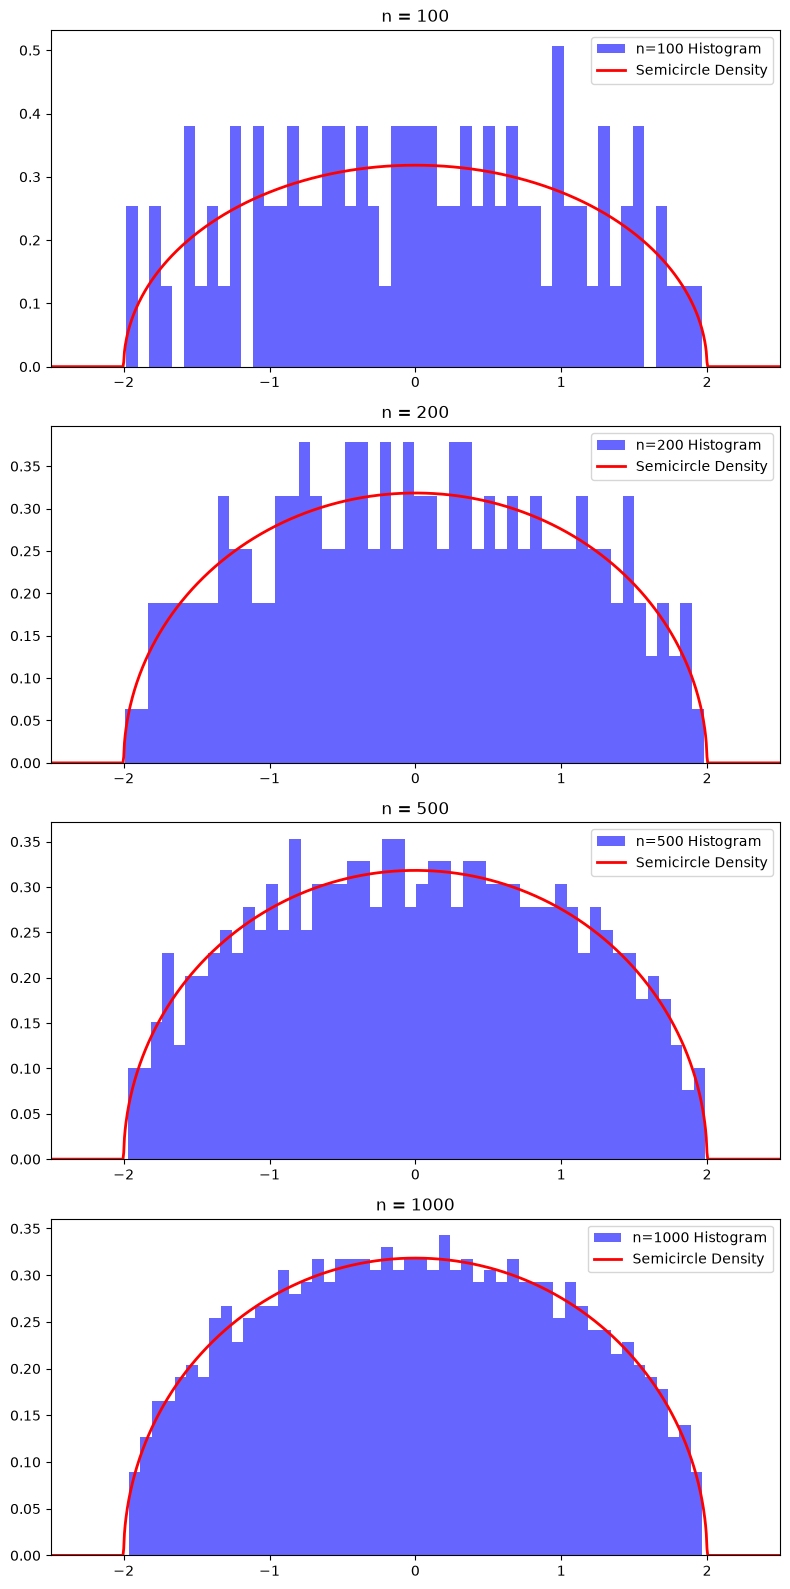

In [3]:
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))

# 准备绘制半圆密度曲线的 x 坐标
x_curve = np.linspace(-2.5, 2.5, 1000)
y_curve = wigner_density(x_curve)

for ax, n in zip(axes, n_values):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    
    # 蓝色标准化直方图
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.6, label=f'n={n} Histogram')
    # 红色半圆密度曲线
    ax.plot(x_curve, y_curve, 'r-', linewidth=2, label='Semicircle Density')
    
    ax.set_title(f'n = {n}')
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

### 说明：从图中可以看出，当 n=500 或 n=1000时，蓝色直方图与红色半圆密度曲线拟合得较好，边缘的波动逐渐减小。

## 2.Conway的生命游戏

In [5]:
# 1. 验证棋盘合法性
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    # 检查元素是否仅为 0 或 1
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

# 2. 单步演化
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘：必须是二维 NumPy 数组且仅包含 0 和 1")
    
    # 使用 np.roll 实现环绕边界，计算 8 个邻居的活细胞总数
    neighbors = (
        np.roll(board, 1, axis=0) + np.roll(board, -1, axis=0) +
        np.roll(board, 1, axis=1) + np.roll(board, -1, axis=1) +
        np.roll(np.roll(board, 1, axis=0), 1, axis=1) +
        np.roll(np.roll(board, 1, axis=0), -1, axis=1) +
        np.roll(np.roll(board, -1, axis=0), 1, axis=1) +
        np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    )
    
    new_board = np.zeros_like(board)
    
    # 规则 1, 2, 3: 活细胞有 2 或 3 个邻居时继续存活
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 规则 4: 死细胞恰好有 3 个邻居时复活
    new_board[(board == 0) & (neighbors == 3)] = 1
    
    return new_board

# 3. 绘制棋盘
def draw_gol_board(board):
    # cmap='gray_r' 保证 0 是白色，1 是黑色
    plt.imshow(board, cmap='gray_r')
    # 不显示网格线、轴标签和轴刻度
    plt.axis('off')
    plt.show()

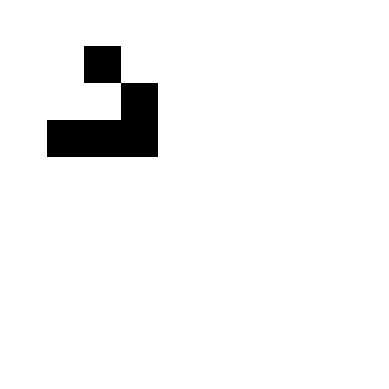

In [7]:
# 创建一个简单的测试棋盘
test_board = np.zeros((10, 10), dtype=int)
test_board[1, 2] = 1
test_board[2, 3] = 1
test_board[3, 1:4] = 1

draw_gol_board(test_board)

## 3.使用pandas DataFrame

In [10]:
import pandas as pd
df = pd.read_csv('iris.csv')

print("数据点数量:", df.shape[0])
print("\n每列数据类型:\n", df.dtypes)
print("\n列名:", df.columns.tolist())
print("\n花卉种类数量:", df['Species'].nunique())
print("\n花卉种类:", df['Species'].unique())

数据点数量: 150

每列数据类型:
 Species                int64
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

列名: ['Species', 'sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

花卉种类数量: 150

花卉种类: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149]


In [13]:
#将Series强制类型转换
df['Species'] = df['Species'].astype(str)
# 注意这里你的列名是带 (cm) 的，使用 .at 逐个赋值最稳妥
# 修改第 35 行
df.at[34, 'sepal length (cm)'] = 4.9
df.at[34, 'sepal width (cm)'] = 3.1
df.at[34, 'petal length (cm)'] = 1.5
df.at[34, 'petal width (cm)'] = 0.2
df.at[34, 'Species'] = "setosa"

# 修改第 38 行
df.at[37, 'sepal length (cm)'] = 4.9
df.at[37, 'sepal width (cm)'] = 3.6
df.at[37, 'petal length (cm)'] = 1.4
df.at[37, 'petal width (cm)'] = 0.1
df.at[37, 'Species'] = "setosa"

# 检查修改结果
print(df.iloc[[34, 37]])

   Species  sepal length (cm)  sepal width (cm)  petal length (cm)  \
34  setosa                4.9               3.1                1.5   
37  setosa                4.9               3.6                1.4   

    petal width (cm)  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  
34               0.2            4.9           3.1            1.5           0.2  
37               0.1            NaN           NaN            NaN           NaN  


In [14]:
# 同样注意列名带上 (cm)，添加比例
df['Petal.Ratio'] = df['petal length (cm)'] / df['petal width (cm)']
df['Sepal.Ratio'] = df['sepal length (cm)'] / df['sepal width (cm)']

df.to_csv('iris_corrected.csv', index=False)
print("已成功保存 iris_corrected.csv")

已成功保存 iris_corrected.csv


In [15]:
result = df.groupby('Species')[['Petal.Ratio', 'Sepal.Ratio']].agg(['mean', 'median', 'min', 'max', 'std'])
result

Petal.Ratio                                           Sepal.Ratio  \
               mean     median       min        max       std        mean   
Species                                                                     
0          7.000000   7.000000  7.000000   7.000000       NaN    1.457143   
1          7.000000   7.000000  7.000000   7.000000       NaN    1.633333   
10         7.500000   7.500000  7.500000   7.500000       NaN    1.459459   
100        2.400000   2.400000  2.400000   2.400000       NaN    1.909091   
101        2.684211   2.684211  2.684211   2.684211       NaN    2.148148   
...             ...        ...       ...        ...       ...         ...   
96         3.230769   3.230769  3.230769   3.230769       NaN    1.965517   
97         3.307692   3.307692  3.307692   3.307692       NaN    2.137931   
98         2.727273   2.727273  2.727273   2.727273       NaN    2.040000   
99         3.153846   3.153846  3.153846   3.153846       NaN    2.035714   
setosa    10.750000  10.750000  7.500000  14.000000  4.596194    1.470878   

                                                 
           median       min       max       std  
Species                                          
0        1.457143  1.457143  1.457143       NaN  
1        1.633333  1.633333  1.633333       NaN  
10       1.459459  1.459459  1.459459       NaN  
100      1.909091  1.909091  1.909091       NaN  
101      2.148148  2.148148  2.148148       NaN  
...           ...       ...       ...       ...  
96       1.965517  1.965517  1.965517       NaN  
97       2.137931  2.137931  2.137931       NaN  
98       2.040000  2.040000  2.040000       NaN  
99       2.035714  2.035714  2.035714       NaN  
setosa   1.470878  1.361111  1.580645  0.155234  

[149 rows x 10 columns]